                      type  missing  distinct    min     max
age                float64        0       104   0.08   82.00
avg_glucose_level  float64        0      3978  55.12  271.74
bmi                float64      203       416  10.30   78.00
ever_married           str        0         2    NaN     NaN
gender                 str        0         2    NaN     NaN
heart_disease        int64        0         2   0.00    1.00
hypertension         int64        0         2   0.00    1.00
residence_type         str        0         2    NaN     NaN
smoking_status         str        0         4    NaN     NaN
stroke               int64        0         2   0.00    1.00
work_type              str        0         5    NaN     NaN
one tree (leaf 20)        : CV ROC AUC 0.751 +/- 0.044   fit 0.01 s
forest (default)          : CV ROC AUC 0.809 +/- 0.027   fit 0.19 s
forest (balanced)         : CV ROC AUC 0.803 +/- 0.021   fit 0.17 s
forest (balanced, leaf 20): CV ROC AUC 0.850 +/- 0.015   fit 0.1

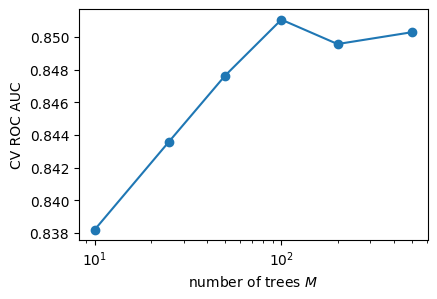

CV ROC AUC (trees): [0.838 0.844 0.848 0.851 0.85  0.85 ]


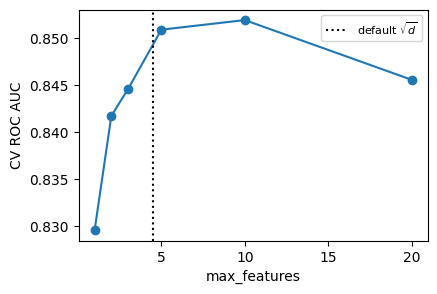

CV ROC AUC (max_features): [0.83  0.842 0.845 0.851 0.852 0.846]


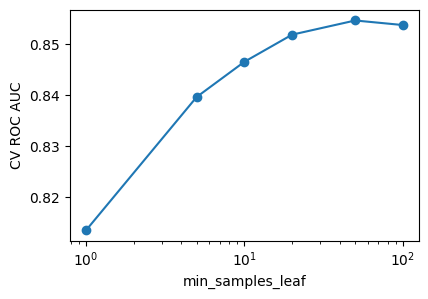

CV ROC AUC (leaf size): [0.813 0.84  0.847 0.852 0.855 0.854]
in-sample ROC AUC 0.951   cross-validated ROC AUC 0.851


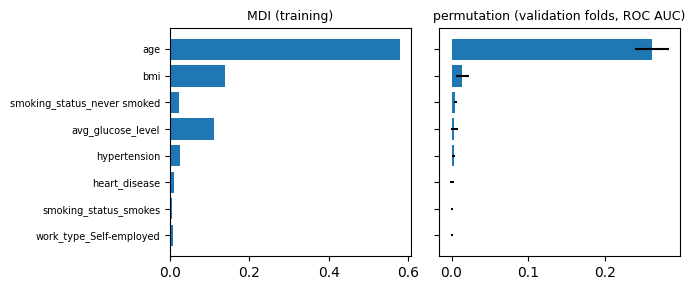

threshold 0.6: precision 0.211, recall 0.513, share flagged 0.118
threshold 0.55: precision 0.207, recall 0.583, share flagged 0.137
threshold 0.5: precision 0.188, recall 0.633, share flagged 0.164
threshold 0.45: precision 0.180, recall 0.709, share flagged 0.192
threshold 0.4: precision 0.165, recall 0.754, share flagged 0.222
threshold 0.35: precision 0.148, recall 0.789, share flagged 0.259
threshold 0.3: precision 0.133, recall 0.814, share flagged 0.297
threshold 0.25: precision 0.119, recall 0.844, share flagged 0.345
threshold 0.2: precision 0.108, recall 0.884, share flagged 0.399
threshold 0.15: precision 0.102, recall 0.930, share flagged 0.445
threshold 0.1: precision 0.092, recall 0.955, share flagged 0.507
chosen threshold: 0.2 (highest with cross-validated recall >= 0.85)


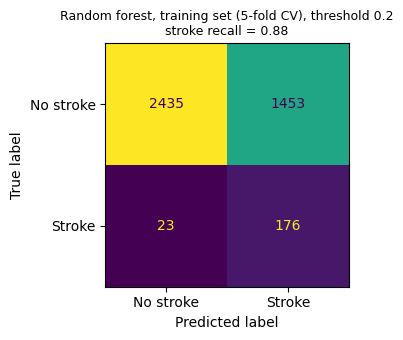

in-sample ROC AUC 0.951   cross-validated ROC AUC 0.851
cross-validated at threshold 0.2: precision 0.108, recall 0.884, share flagged 0.399
prediction time on 4087 training rows: 0.042 s (10.2 ms per 1000 rows)


In [1]:
# 1. Imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_score, cross_val_predict
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, precision_score, recall_score, ConfusionMatrixDisplay

# 2. Data and cleaning (the test split is discarded and never used)

METRIC = "roc_auc"
TARGET = "stroke"

def overview(d):
    numbers = d.select_dtypes("number")
    return pd.DataFrame({"type": d.dtypes.astype(str), "missing": d.isna().sum(),
                         "distinct": d.nunique(), "min": numbers.min(), "max": numbers.max()})

raw = pd.read_csv("stroke-prediction.csv")
df = raw.drop(columns="id")
df.loc[df["bmi"] > 80, "bmi"] = np.nan          # implausible BMIs -> missing
df = df[df["gender"] != "Other"]                 # single 'Other' row removed
df = df.dropna(subset=[TARGET])                  # rows without a target cannot be used
print(overview(df))

X = pd.get_dummies(df.drop(columns=TARGET))      # text columns -> 0/1 columns; missing BMIs kept (forests accept them)
y = df[TARGET]
X_train, _, y_train, _ = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)   # same training set as the group
cv = StratifiedKFold(5, shuffle=True, random_state=0)  # how to split: 5 stratified folds


# 3. One tree vs forests, same folds

for name, m in [("one tree (leaf 20)        ", DecisionTreeClassifier(min_samples_leaf=20, random_state=0)),
                ("forest (default)          ", RandomForestClassifier(200, random_state=0, n_jobs=-1)),
                ("forest (balanced)         ", RandomForestClassifier(200, class_weight="balanced", random_state=0, n_jobs=-1)),
                ("forest (balanced, leaf 20)", RandomForestClassifier(200, class_weight="balanced", min_samples_leaf=20, random_state=0, n_jobs=-1))]:
    r = cross_validate(m, X_train, y_train, cv=cv, scoring="roc_auc")
    print(f"{name}: CV ROC AUC {r['test_score'].mean():.3f} +/- {r['test_score'].std():.3f}   fit {r['fit_time'].mean():.2f} s")


# 4. How many trees?

Mv = [10, 25, 50, 100, 200, 500]
auc = [cross_val_score(RandomForestClassifier(M, class_weight="balanced", min_samples_leaf=20, random_state=0, n_jobs=-1),
                       X_train, y_train, cv=cv, scoring="roc_auc").mean() for M in Mv]
fig, ax = plt.subplots(figsize=(4.5, 3))
ax.semilogx(Mv, auc, "o-")
ax.set_xlabel("number of trees $M$")
ax.set_ylabel("CV ROC AUC")
plt.show()
print("CV ROC AUC (trees):", np.round(auc, 3))


# 5. How many features per split?

d = X.shape[1]
mfs = [1, 2, 3, 5, 10, d]
auc = [cross_val_score(RandomForestClassifier(200, max_features=k, class_weight="balanced", min_samples_leaf=20,
                                              random_state=0, n_jobs=-1),
                       X_train, y_train, cv=cv, scoring="roc_auc").mean() for k in mfs]
fig, ax = plt.subplots(figsize=(4.5, 3))
ax.plot(mfs, auc, "o-")
ax.axvline(np.sqrt(d), color="k", linestyle=":", label=r"default $\sqrt{d}$")
ax.set_xlabel("max_features")
ax.set_ylabel("CV ROC AUC")
ax.legend(fontsize=8)
plt.show()
print("CV ROC AUC (max_features):", np.round(auc, 3))


# 6. Leaf size

leaves = [1, 5, 10, 20, 50, 100]
auc = [cross_val_score(RandomForestClassifier(200, max_features=10, min_samples_leaf=L, class_weight="balanced",
                                              random_state=0, n_jobs=-1),
                       X_train, y_train, cv=cv, scoring="roc_auc").mean() for L in leaves]
fig, ax = plt.subplots(figsize=(4.5, 3))
ax.semilogx(leaves, auc, "o-")
ax.set_xlabel("min_samples_leaf")
ax.set_ylabel("CV ROC AUC")
plt.show()
print("CV ROC AUC (leaf size):", np.round(auc, 3))


# 7. Final forest, evaluated by cross-validation on the training set

rf = RandomForestClassifier(200, max_features=10, min_samples_leaf=20, class_weight="balanced",
                            random_state=0, n_jobs=-1)
proba_cv = cross_val_predict(rf, X_train, y_train, cv=cv, method="predict_proba")[:, 1]   # each row predicted by a forest that did not see it
rf.fit(X_train, y_train)
print(f"in-sample ROC AUC {roc_auc_score(y_train, rf.predict_proba(X_train)[:, 1]):.3f}   "
      f"cross-validated ROC AUC {roc_auc_score(y_train, proba_cv):.3f}")


# 8. Importances (permutation on each validation fold, averaged)

pi_folds = []
for tr, va in cv.split(X_train, y_train):
    m = RandomForestClassifier(200, max_features=10, min_samples_leaf=20, class_weight="balanced",
                               random_state=0, n_jobs=-1).fit(X_train.iloc[tr], y_train.iloc[tr])
    pi_folds.append(permutation_importance(m, X_train.iloc[va], y_train.iloc[va], n_repeats=10,
                                           random_state=0, scoring="roc_auc").importances_mean)
pi_mean, pi_std = np.mean(pi_folds, axis=0), np.std(pi_folds, axis=0)
names = X.columns.to_numpy()
top = np.argsort(pi_mean)[::-1][:8]
fig, axs = plt.subplots(1, 2, figsize=(7, 3), sharey=True)
axs[0].barh(range(8)[::-1], rf.feature_importances_[top])
axs[0].set_title("MDI (training)", fontsize=9)
axs[1].barh(range(8)[::-1], pi_mean[top], xerr=pi_std[top])
axs[1].set_title("permutation (validation folds, ROC AUC)", fontsize=9)
axs[0].set_yticks(range(8)[::-1], names[top], fontsize=7)
plt.tight_layout()
plt.show()


# 9. Confusion matrix at the chosen threshold (cross-validated predictions)

TARGET_RECALL = 0.85   # the group's target
thresholds = [0.6, 0.55, 0.5, 0.45, 0.4, 0.35, 0.3, 0.25, 0.2, 0.15, 0.1]
for t in thresholds:
    p = (proba_cv >= t).astype(int)
    print(f"threshold {t}: precision {precision_score(y_train, p, zero_division=0):.3f}, "
          f"recall {recall_score(y_train, p):.3f}, share flagged {p.mean():.3f}")
THRESHOLD = max(t for t in thresholds if recall_score(y_train, (proba_cv >= t).astype(int)) >= TARGET_RECALL)
p_cv = (proba_cv >= THRESHOLD).astype(int)
print(f"chosen threshold: {THRESHOLD} (highest with cross-validated recall >= {TARGET_RECALL})")

fig, ax = plt.subplots(figsize=(4, 3.5))
ConfusionMatrixDisplay.from_predictions(y_train, p_cv, display_labels=["No stroke", "Stroke"],
                                        cmap="viridis", colorbar=False, ax=ax)
ax.set_title(f"Random forest, training set (5-fold CV), threshold {THRESHOLD}\n"
             f"stroke recall = {recall_score(y_train, p_cv):.2f}", fontsize=9)
plt.tight_layout()
plt.show()

# 10. Final summary on the training set only (test set not used)
#     Reuses proba_cv and rf from section 7, and THRESHOLD and p_cv from section 9.
import time

t0 = time.perf_counter()
proba_fit = rf.predict_proba(X_train)[:, 1]      # in-sample predictions, only to time prediction and show the gap
pred_time = time.perf_counter() - t0

print(f"in-sample ROC AUC {roc_auc_score(y_train, proba_fit):.3f}   "
      f"cross-validated ROC AUC {roc_auc_score(y_train, proba_cv):.3f}")
print("cross-validated at threshold {}: precision {:.3f}, recall {:.3f}, share flagged {:.3f}".format(
    THRESHOLD, precision_score(y_train, p_cv, zero_division=0), recall_score(y_train, p_cv), p_cv.mean()))
print(f"prediction time on {len(X_train)} training rows: {pred_time:.3f} s "
      f"({pred_time / len(X_train) * 1e6:.1f} ms per 1000 rows)")